# Entender quien escribe mal: resultados

Antes de abrir este notebook hay que correr `uv run python experimento.py`, que genera `results/metrics.csv` y `results/predictions.parquet`.

In [1]:
import pandas as pd

from tp import plots
from tp.data import RESULTS_DIR, SEED  # noqa: F401 (se usa como @SEED en query)
from tp.plots import MODEL_LABELS, PERTURBATION_LABELS

pd.set_option("display.precision", 3)
metrics = pd.read_csv(RESULTS_DIR / "metrics.csv")
predictions = pd.read_parquet(RESULTS_DIR / "predictions.parquet")
models = [m for m in MODEL_LABELS if m in set(metrics["model"])]
models

/mnt/sata/backups/Estudio/Universidad/procesamiento_lenguaje_natural/tpi/nlp_tp_2026/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


['tfidf_word', 'tfidf_char', 'fasttext_word', 'fasttext', 'beto']

## 1. Rendimiento sin ruido (validation)

Se reporta sobre validation porque los hiperparámetros se eligieron con test: el rendimiento en test está sesgado a favor de los modelos ajustados. La columna `f1_macro_test` se muestra solo como referencia.

In [2]:
from tp.evaluation import average_seeds

# Promedio de las semillas de entrenamiento; _std es el desvío entre ellas.
avg = average_seeds(metrics).query("perturbation == 'clean'")
cols = ["accuracy", "accuracy_std", "f1_macro", "f1_macro_std", "n_seeds"]
clean = avg.query("split == 'validation'").set_index("model").loc[models, cols]
clean["f1_macro_test"] = avg.query("split == 'test'").set_index("model")["f1_macro"]
clean.rename(index=MODEL_LABELS)

,accuracy,f1_macro
model,,
TF-IDF palabras,0.808,0.782
TF-IDF caracteres,0.827,0.794
FastText sin subpalabras,0.784,0.758
FastText con subpalabras,0.807,0.771
BETO,0.868,0.811


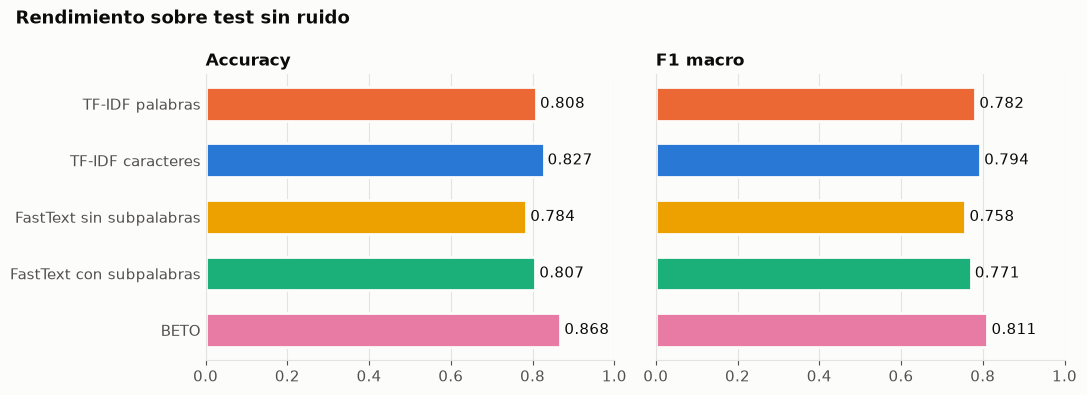

In [3]:
plots.plot_clean(metrics);

## 2. Ejemplos de cada perturbación

In [4]:
from tp.perturbations import PERTURBATIONS, perturb

ejemplos = predictions.query(
    "model == @models[0] and perturbation == 'clean' and split == 'validation'"
)["original"]
frases = ejemplos.sample(4, random_state=1).tolist()
pd.DataFrame(
    {PERTURBATION_LABELS[n]: perturb(frases, n, 0.5) for n in PERTURBATIONS},
    index=frases,
).T

,dime la hora,está mi alarma de la escuela puesta,pon una canción,que día es hoy
Sin tildes,dime la hora,está mi alarma de la escuela puesta,pon una canción,que dia es hoy
Minúsculas y sin puntuación,dime la hora,está mi alarma de la escuela puesta,pon una canción,que día es hoy
Errores de tipeo,dime la hora,está mi slarma de la escuela puest,on una canfión,que ddía es hoy
Abreviaturas,dime la hora,está mi alarma d la escuela puesta,pon una canción,que día es hoy
Expresiones coloquiales,dime la hora,está mi alarma de la escuela puesta,pon una tema,que día es hoy
Combinado,decime la hor,esgá mi alarma d la scuela puesta,po ina cnación,q diia es hoy


## 3. Degradación frente al ruido (validation)

Las curvas usan F1 macro. Las líneas punteadas son los modelos que ven palabras completas.

In [5]:
val = metrics[metrics["split"] == "validation"]
tabla = val.pivot_table(
    index=["perturbation", "intensity"], columns="model", values="f1_macro"
)[models]
tabla.rename(columns=MODEL_LABELS)

model                     TF-IDF palabras  TF-IDF caracteres  \
perturbation   intensity                                       
abbreviations  0.10                 0.780              0.808   
               0.25                 0.782              0.806   
               0.50                 0.773              0.806   
               0.75                 0.772              0.802   
               1.00                 0.771              0.798   
clean          0.00                 0.780              0.807   
colloquial     0.10                 0.774              0.799   
               0.25                 0.752              0.784   
               0.50                 0.745              0.778   
               0.75                 0.710              0.760   
               1.00                 0.685              0.744   
lower_no_punct 0.10                 0.780              0.807   
               0.25                 0.780              0.808   
               0.50                 0.780              0.808   
               0.75                 0.780              0.808   
               1.00                 0.780              0.808   
mixed          0.10                 0.719              0.774   
               0.25                 0.671              0.756   
               0.50                 0.499              0.689   
               0.75                 0.299              0.615   
               1.00                 0.058              0.519   
no_accents     0.10                 0.779              0.808   
               0.25                 0.772              0.807   
               0.50                 0.765              0.802   
               0.75                 0.758              0.813   
               1.00                 0.750              0.810   
typos          0.10                 0.735              0.790   
               0.25                 0.676              0.766   
               0.50                 0.538              0.757   
               0.75                 0.361              0.679   
               1.00                 0.087              0.634   

model                     FastText sin subpalabras  FastText con subpalabras  \
perturbation   intensity                                                       
abbreviations  0.10                          0.763                     0.794   
               0.25                          0.757                     0.787   
               0.50                          0.751                     0.808   
               0.75                          0.746                     0.799   
               1.00                          0.739                     0.794   
clean          0.00                          0.764                     0.795   
colloquial     0.10                          0.761                     0.794   
               0.25                          0.731                     0.769   
               0.50                          0.714                     0.765   
               0.75                          0.677                     0.751   
               1.00                          0.644                     0.724   
lower_no_punct 0.10                          0.764                     0.795   
               0.25                          0.764                     0.795   
               0.50                          0.763                     0.795   
               0.75                          0.764                     0.795   
               1.00                          0.764                     0.795   
mixed          0.10                          0.706                     0.757   
               0.25                          0.621                     0.745   
               0.50                          0.465                     0.628   
               0.75                          0.247                     0.558   
               1.00                          0.053                     0.443   
no_accents     0.10                          0.

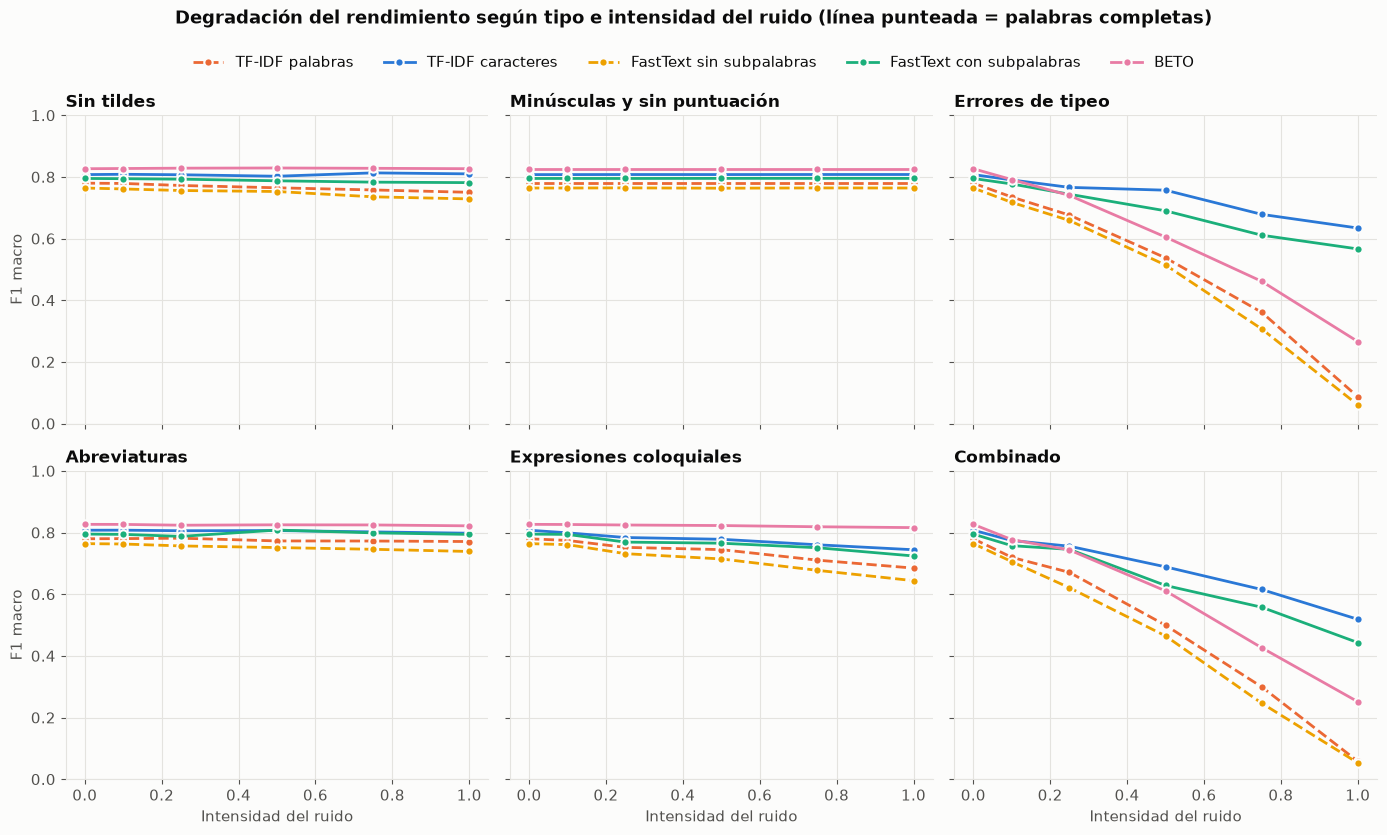

In [6]:
plots.plot_degradation(metrics);

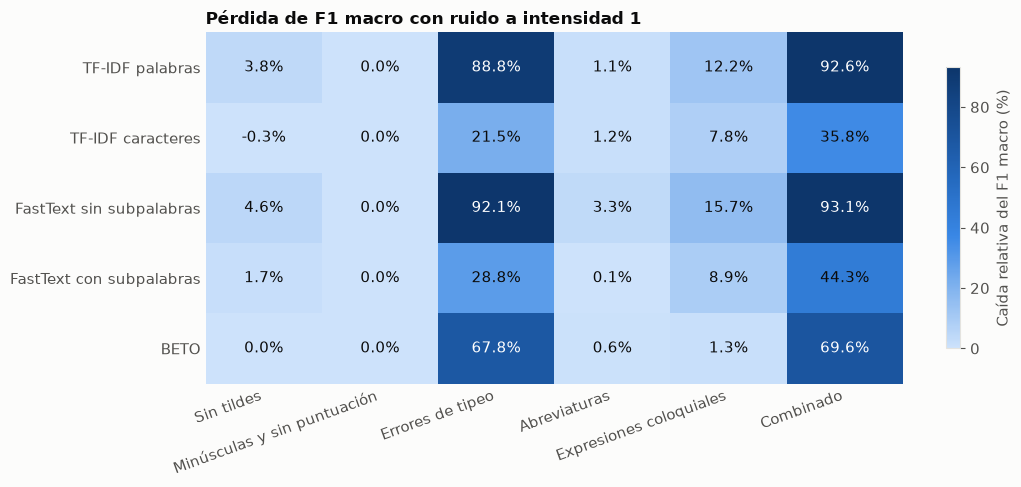

In [7]:
plots.plot_drop_heatmap(metrics, intensity=1.0);

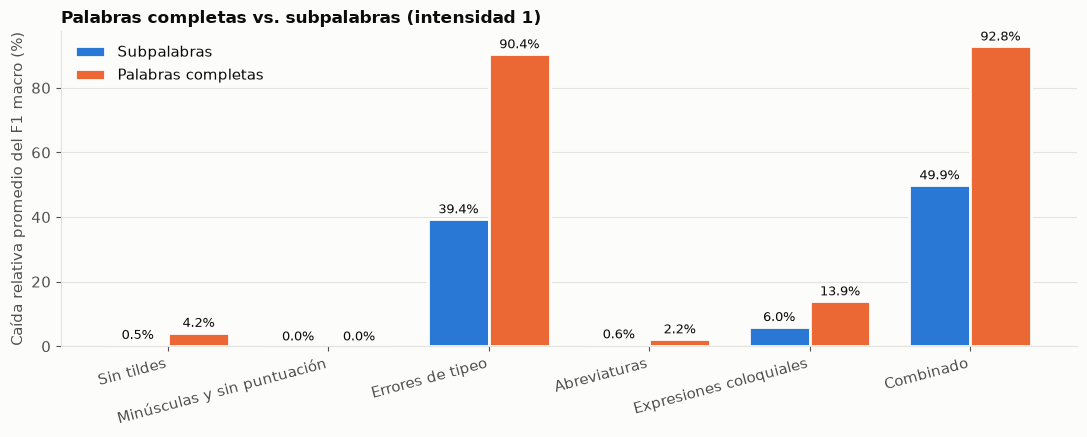

In [8]:
plots.plot_word_vs_subword(metrics, intensity=1.0);

### Caídas con intervalo de confianza

Diferencia de caídas de accuracy entre dos modelos (bootstrap pareado sobre frases, IC 95 %). Positiva: el primer modelo cae más. Si el intervalo no incluye 0, la diferencia no se explica por la muestra de frases. `fasttext_word` contra `fasttext` aísla el efecto de las subpalabras.

In [ ]:
from tp.evaluation import compare_drops

compare_drops(predictions, "fasttext_word", "fasttext").query(
    "split == 'validation'"
).round(3)

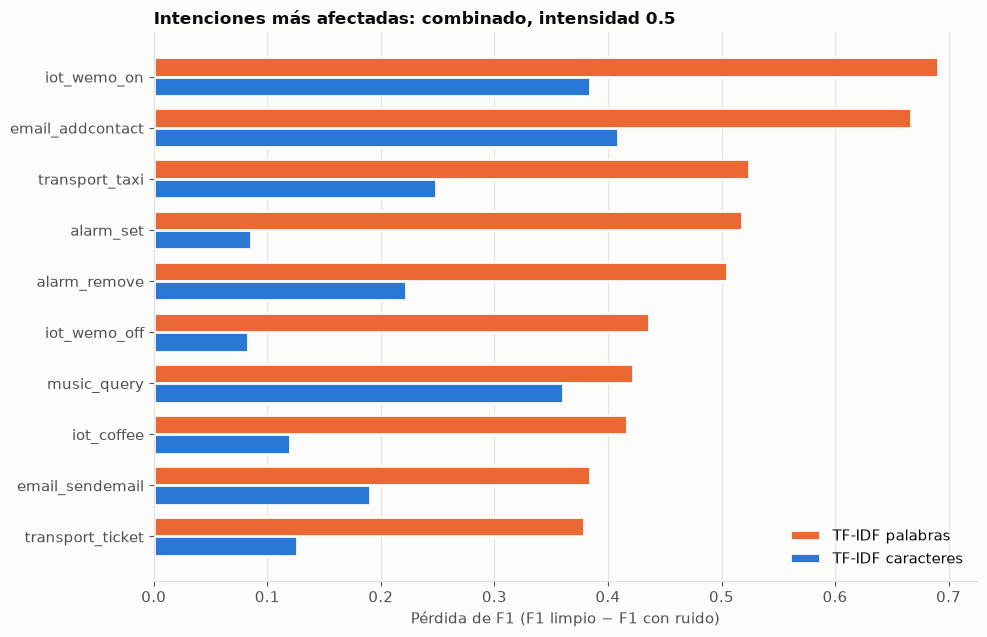

In [9]:
plots.plot_intent_drop(
    predictions,
    models=("tfidf_word", "tfidf_char"),
    perturbation="mixed",
    intensity=0.5,
);

## 4. Análisis de errores

Frases en las que un modelo acierta y el otro falla con la misma entrada perturbada.

In [10]:
def contrastar(acierta, falla, perturbation="typos", intensity=0.5, n=10, seed=0):
    sel = predictions.query(
        "split == 'validation' and perturbation == @perturbation"
        " and intensity == @intensity and seed == @SEED and train_seed == @SEED"
    )
    a = sel[sel["model"] == acierta].set_index("idx")
    b = sel[sel["model"] == falla].set_index("idx")
    mask = (a["pred"] == a["label"]) & (b["pred"] != b["label"])
    print(f"{mask.sum()} frases donde {acierta} acierta y {falla} falla")
    out = a.loc[mask, ["original", "text", "label"]].assign(
        **{f"pred_{falla}": b.loc[mask, "pred"]}
    )
    return out.sample(min(n, len(out)), random_state=seed)


contrastar("tfidf_char", "tfidf_word", "typos", 0.5)

476 frases donde tfidf_char acierta y tfidf_word falla


,original,text,label,pred_tfidf_word
idx,,,,
1077,abre los cuarenta estación rock,aber los cuuarenta estació rock,play_radio,play_music
668,el tiempo se actualiza al usar segundos por ti...,el yiempo se actualiza al jsar seegundos lor t...,weather_query,calendar_set
1351,quiero escuchar el podcast de mcs,quiero ecuchar el poddcast de mcz,play_podcasts,play_audiobook
1519,cuanto cuesta un billete de tren a madrid,cuanto cueta un billeet de tre a mdrid,transport_query,recommendation_locations
408,pon música de los beatles,po músicca de los batles,play_music,qa_factoid
1873,ok google tuitea que el servicio en la yoselén...,ok google tuiyea qe el sevicio en la yoseln es...,social_post,qa_factoid
1629,describir una patata,desscribir un patata,qa_definition,cooking_recipe
1279,por favor dime que listas he hecho,or favor eime uqe lists he hechoo,lists_query,general_quirky
326,silenciar el sonido de los altavoces,silfnciar el sonnido de lo altavoces,audio_volume_mute,audio_volume_up


In [11]:
contrastar("tfidf_word", "tfidf_char", "typos", 0.5)

71 frases donde tfidf_word acierta y tfidf_char falla


,original,text,label,pred_tfidf_char
idx,,,,
926,cómo será mi mañana mañana,ccómo será mi mañana mañana,calendar_query,weather_query
944,que pasa este fin de semana,que passa etse ein de seana,calendar_query,qa_factoid
1580,resume todas las cosas que podría hacer por mí...,resum todass las cñsas que podría hacer pñr mí...,general_quirky,play_music
790,chismeando sobre famosos,chismeano sobre famosos,general_quirky,qa_factoid
1004,quiero quedar con sara mañana,quiiero quedar con aara mapana,calendar_set,qa_factoid
1590,quiénes son los mejores artistas de hip hop,quiéne soon los ejores artistas de ip ho,qa_factoid,play_music
486,por favor no contestes,por favor no contestes,audio_volume_mute,email_sendemail
1724,características del ipad air,característiacs ddel iapd air,general_quirky,qa_factoid
1140,tomemos un descanso de cinco minutos,tomemos un descanso de cinco munutos,play_audiobook,general_quirky


In [12]:
contrastar("fasttext", "fasttext_word", "colloquial", 1.0)

238 frases donde fasttext acierta y fasttext_word falla


,original,text,label,pred_fasttext_word
idx,,,,
1622,los chupitos de gelatina no tienen calorías,los chupitos de gelatina no tienen calorías,qa_factoid,calendar_remove
1361,muéstrame los podcasts mejor calificados,muéstrame los podcasts mejor calificados,play_podcasts,general_quirky
783,consejos recientes sobre seo en google,consejos recientes sobre seo en google,general_quirky,qa_factoid
869,cuando esta programada la boda,cuando esta programada la boda,calendar_query,general_quirky
1038,por favor borra todos los recordatorios del do...,por favor borrá todos los recordatorios del do...,calendar_remove,calendar_set
1985,quiero encontrar correos electrónicos de juan ...,quiero encontrar mails de juan con el asunto q...,email_query,email_querycontact
1031,necesito que me recuerden las reuniones del lunes,me hace falta que me recuerden las reuniones d...,calendar_set,calendar_query
1947,revisa mis correo s,revisa mis mail s,email_query,general_greet
285,cual es el estado de mi ultimo pedido,cual es el estado de mi ultimo pedido,takeaway_query,calendar_query


Confusiones más frecuentes de un modelo con una perturbación dada:

In [13]:
def confusiones(model, perturbation="mixed", intensity=0.5, top=10):
    sel = predictions.query(
        "split == 'validation' and model == @model"
        " and perturbation == @perturbation and intensity == @intensity"
        " and seed == @SEED and train_seed == @SEED"
    )
    err = sel[sel["label"] != sel["pred"]]
    return (
        err.groupby(["label", "pred"])
        .size()
        .sort_values(ascending=False)
        .head(top)
        .rename("errores")
    )


confusiones("tfidf_word")

label            pred          
play_music       general_quirky    21
email_sendemail  general_quirky    15
general_quirky   qa_factoid        15
calendar_query   general_quirky    15
qa_factoid       general_quirky    14
weather_query    calendar_query    13
calendar_set     general_quirky    13
news_query       general_quirky    12
weather_query    general_quirky    11
play_radio       play_music        10
Name: errores, dtype: int64

## 5. Probar frases propias

Carga los modelos entrenados y muestra la predicción de cada uno para la frase original y sus versiones con ruido.

In [14]:
from tp.models import MODELS, cache_path

# Modelos entrenados con la semilla principal.
cargados = {}
for m in models:
    model = MODELS[m]()
    cargados[m] = model.load(cache_path(m, model))


def probar(frase, intensity=0.5):
    variantes = {"Original": frase} | {
        PERTURBATION_LABELS[n]: perturb([frase], n, intensity)[0] for n in PERTURBATIONS
    }
    textos = list(variantes.values())
    tabla = pd.DataFrame({"texto": textos}, index=list(variantes))
    for m, model in cargados.items():
        tabla[MODEL_LABELS[m]] = model.predict(textos)
    return tabla


probar("ponme una alarma para mañana a las siete por favor")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   6%|▋         | 13/201 [00:00<00:02, 67.85it/s]

Loading weights:  14%|█▍        | 28/201 [00:00<00:01, 96.70it/s]

Loading weights:  25%|██▍       | 50/201 [00:00<00:01, 136.73it/s]

Loading weights:  32%|███▏      | 65/201 [00:00<00:01, 134.23it/s]

Loading weights:  44%|████▍     | 89/201 [00:00<00:00, 162.81it/s]

... (3 outputs left out)

Loading weights:  78%|███████▊  | 156/201 [00:01<00:00, 137.84it/s]

Loading weights:  89%|████████▉ | 179/201 [00:01<00:00, 131.87it/s]

Loading weights: 100%|██████████| 201/201 [00:01<00:00, 147.27it/s]

,texto,TF-IDF palabras,TF-IDF caracteres,FastText sin subpalabras,FastText con subpalabras,BETO
Original,ponme una alarma para mañana a las siete por f...,alarm_set,alarm_set,alarm_set,alarm_set,alarm_set
Sin tildes,ponme una alarma para mañana a las siete por f...,alarm_set,alarm_set,alarm_set,alarm_set,alarm_set
Minúsculas y sin puntuación,ponme una alarma para mañana a las siete por f...,alarm_set,alarm_set,alarm_set,alarm_set,alarm_set
Errores de tipeo,ponme una alarma oara mañana a la sete por favñr,alarm_set,alarm_set,alarm_set,alarm_set,alarm_set
Abreviaturas,ponme una alarma pa mañana a las siete xfa,alarm_set,alarm_set,alarm_set,alarm_set,alarm_set
Expresiones coloquiales,ponme una alarma para mañana a las siete por f...,alarm_set,alarm_set,alarm_set,alarm_set,alarm_set
Combinado,poneme una alarma pra mñnn a las 7 por favor,alarm_set,alarm_set,alarm_set,alarm_set,alarm_set


In [15]:
probar("envía un correo electrónico a mi jefe diciendo que llego tarde", intensity=1.0)

,texto,TF-IDF palabras,TF-IDF caracteres,FastText sin subpalabras,FastText con subpalabras,BETO
Original,envía un correo electrónico a mi jefe diciendo...,email_sendemail,email_sendemail,email_sendemail,email_sendemail,email_sendemail
Sin tildes,envia un correo electronico a mi jefe diciendo...,email_sendemail,email_sendemail,email_sendemail,email_sendemail,email_sendemail
Minúsculas y sin puntuación,envía un correo electrónico a mi jefe diciendo...,email_sendemail,email_sendemail,email_sendemail,email_sendemail,email_sendemail
Errores de tipeo,envíía un correo wlectrónico a mi jef diciendd...,email_sendemail,email_sendemail,email_sendemail,email_sendemail,email_sendemail
Abreviaturas,envía un correo electrónico a mi jefe diciendo...,email_sendemail,email_sendemail,email_sendemail,email_sendemail,email_sendemail
Expresiones coloquiales,mandá un mail a mi jefe diciendo que llego tarde,social_post,email_sendemail,calendar_set,email_sendemail,email_sendemail
Combinado,nanda un mmail a mi jfee dociendo q lelgo tard,social_post,calendar_set,general_quirky,calendar_set,play_radio
